In [1]:
from pathlib import Path
from CITNP.datasets.dataset_generator import InterventionDatasetGenerator
from CITNP.models.causalinferencemodel import CausalInferenceModel
import torch
from functools import partial
from CITNP.utils.datautils import transformer_inference_split_withpadding
from CITNP.trainer.causalinferencetrainer import send_to_device
import matplotlib.pyplot as plt
import numpy as np

In [8]:
model_path = Path(
    "/vol/bitbucket/ad6013/Research/CausalInferenceNeuralProcess/CITNP/experiments/results/sin_condition/model_9.pt"
)

In [9]:
DATA_ARGS = {
    "sample_size": 1000,
    "num_variables": 2,
    "function_generator": "sinusoid",
    "graph_type": ["ER"],
    "graph_degrees": [1],
    "iterations_per_epoch": 1,
    "batch_size": 1,
}

train_dataset = InterventionDatasetGenerator(
    **DATA_ARGS
)
collator = partial(
    transformer_inference_split_withpadding,
    cntxt_split=[0.2, 1],
    sample_size=1000,
)
loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=None, shuffle=False,
    num_workers=0, pin_memory=True,
    persistent_workers=False,
    collate_fn=collator(),
)

In [10]:
MODEL_ARGS = {
    "d_model": 512,
    "emb_depth": 2,
    "dim_feedforward": 2048,
    "nhead": 8,
    "dropout": 0.0,
    "num_layers_encoder": 8,
    "num_nodes": 2,
    "device": "cpu",
    "dtype": torch.float32,
}

model = CausalInferenceModel(
    **MODEL_ARGS
)
model.load_state_dict(torch.load(model_path))

<All keys matched successfully>

In [13]:
import matplotlib.pyplot as plt
import numpy as np

def plot_context_target_predictions(context, target, new_target, pred_mean, pred_std, treatment_idx, outcome_index):
    # Convert torch tensors to numpy arrays if necessary
    if hasattr(context, "cpu"):
        context = context.cpu().detach().numpy()
    if hasattr(target, "cpu"):
        target = target.cpu().detach().numpy()
    if hasattr(new_target, "cpu"):
        new_target = new_target.cpu().detach().numpy()
    if hasattr(pred_mean, "cpu"):
        pred_mean = pred_mean.cpu().detach().numpy()
    if hasattr(pred_std, "cpu"):
        pred_std = pred_std.cpu().detach().numpy()

    # Extract treatment and outcome columns from context and target.
    if context.ndim > 1:
        context_treatment = np.squeeze(context[:, :, treatment_idx])
        context_outcome = np.squeeze(context[:, :, outcome_index])
    else:
        raise ValueError("Context data must be multi-dimensional (at least two columns for treatment and outcome).")

    if target.ndim > 1:
        target_treatment = np.squeeze(target[:, :, treatment_idx])
        target_outcome = np.squeeze(target[:, :, outcome_index])
    else:
        raise ValueError("Target data must be multi-dimensional (at least two columns for treatment and outcome).")

    # Extract treatment for new_target.
    new_target_treatment = np.squeeze(new_target[:, :, treatment_idx])

    # Squeeze prediction outputs
    pred_mean_outcome = np.squeeze(pred_mean)
    pred_std_outcome = np.squeeze(pred_std)

    # Create the plot.
    plt.figure(figsize=(10, 6))

    # Plot context and target data points.
    plt.scatter(context_treatment, context_outcome, color='blue', label='Context')
    plt.scatter(target_treatment, target_outcome, color='red', label='Target', alpha=0.5)

    # Plot the predicted mean as a line.
    plt.plot(new_target_treatment, pred_mean_outcome, 'g-', label='Predicted Mean')

    # Fill the area between pred_mean ± pred_std.
    plt.fill_between(new_target_treatment,
                     pred_mean_outcome - 2 * pred_std_outcome,
                     pred_mean_outcome + 2 * pred_std_outcome,
                     color='green', alpha=0.3, label='Prediction Std')

    plt.xlabel('Treatment')
    plt.ylabel('Outcome')
    plt.title('Treatment vs Outcome for Context and Target')
    plt.legend()
    plt.grid(True)
    plt.show()
    plt.clf()


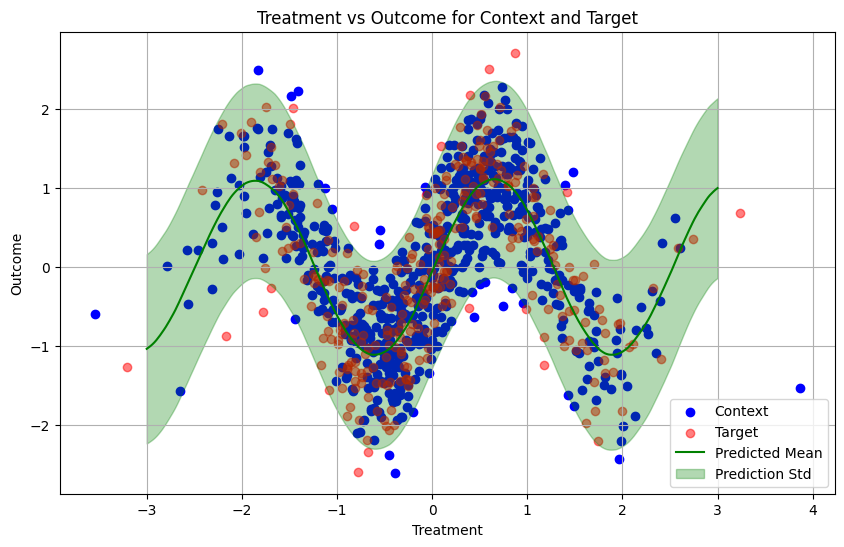

<Figure size 640x480 with 0 Axes>

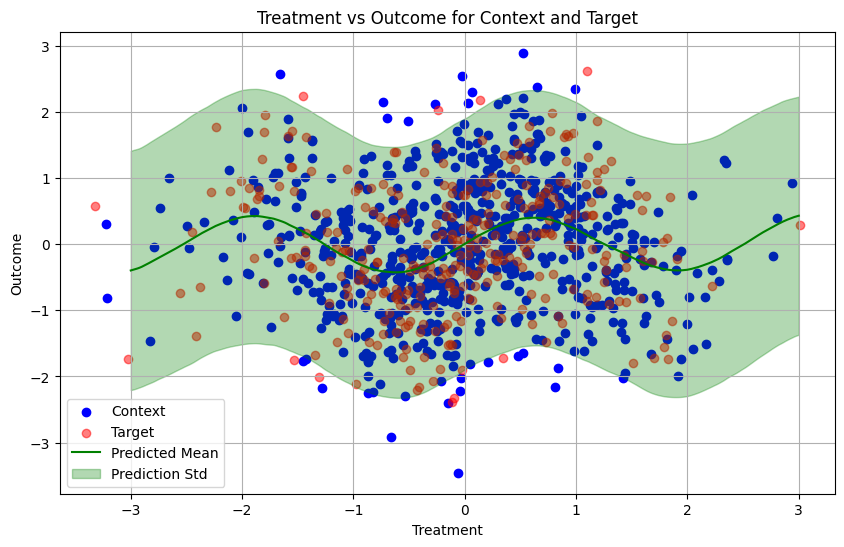

<Figure size 640x480 with 0 Axes>

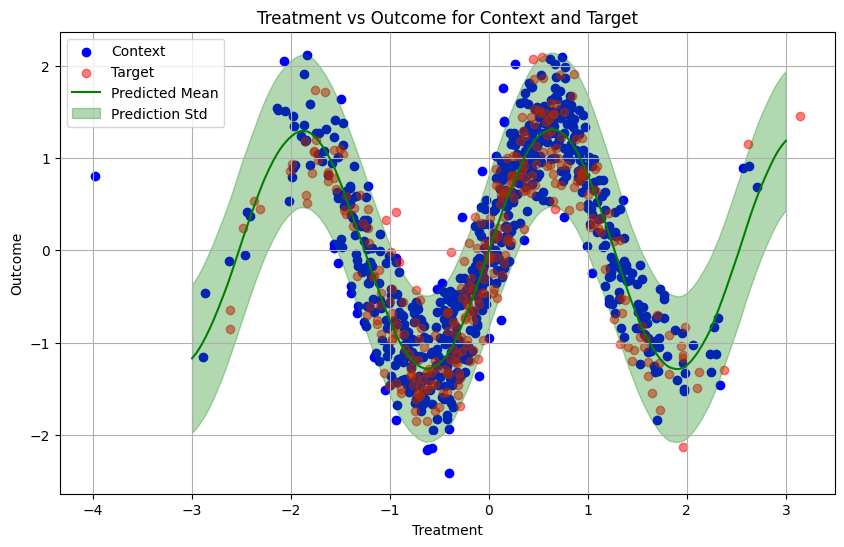

<Figure size 640x480 with 0 Axes>

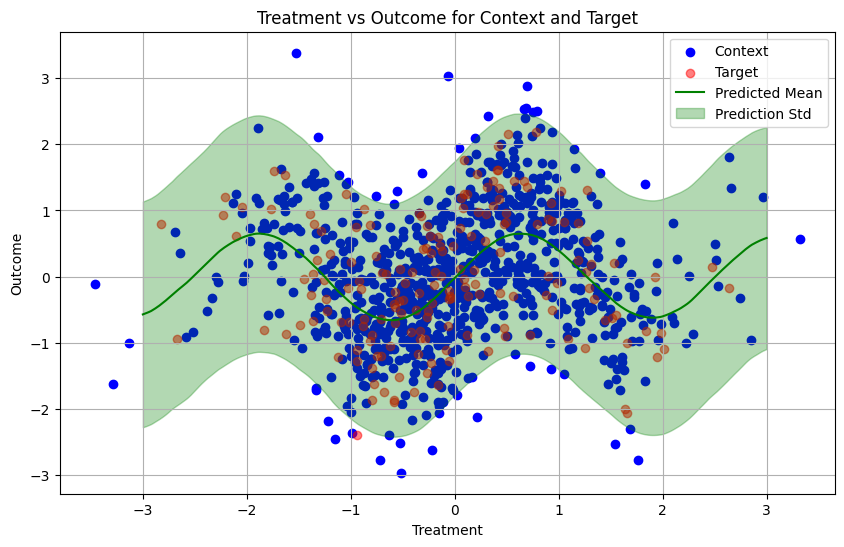

<Figure size 640x480 with 0 Axes>

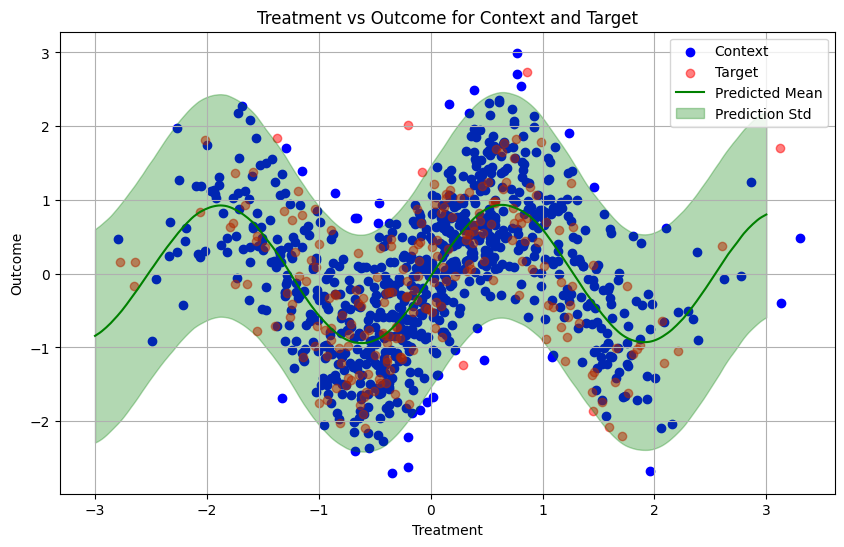

<Figure size 640x480 with 0 Axes>

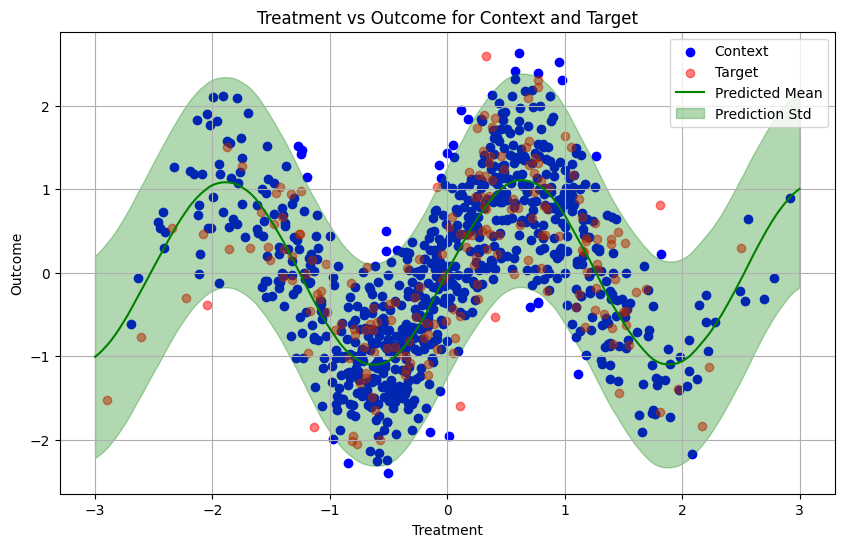

<Figure size 640x480 with 0 Axes>

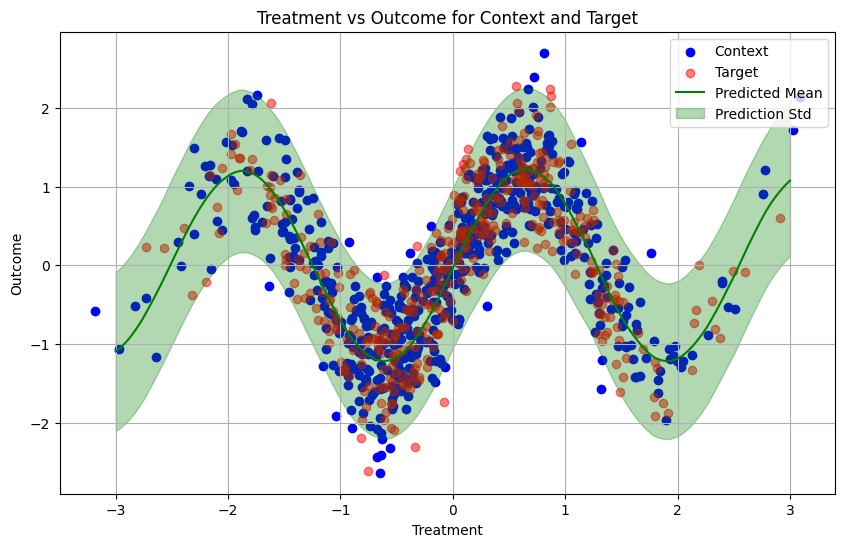

<Figure size 640x480 with 0 Axes>

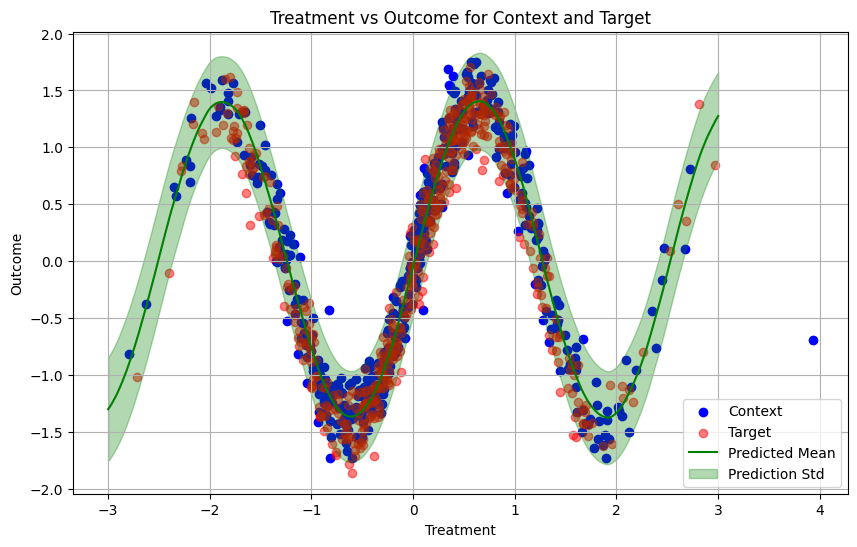

<Figure size 640x480 with 0 Axes>

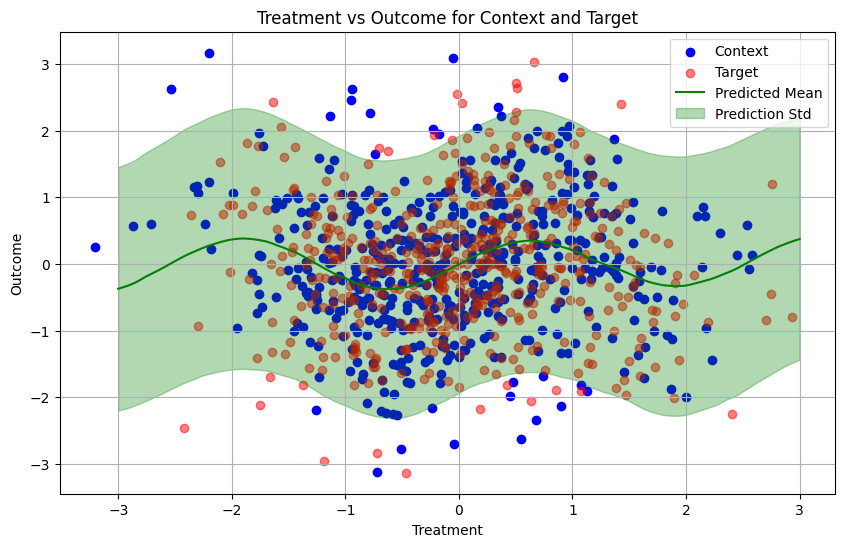

<Figure size 640x480 with 0 Axes>

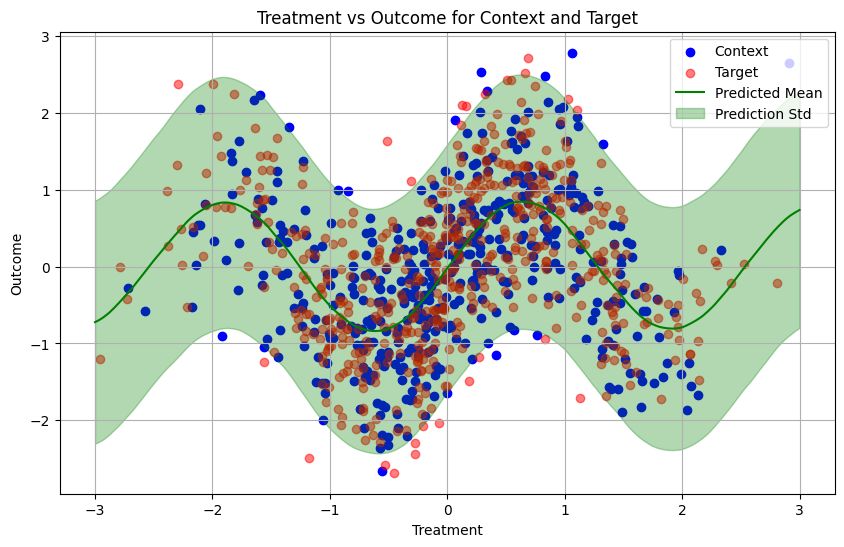

<Figure size 640x480 with 0 Axes>

In [14]:
DEVICE = "cuda"

model.train()
model.to(DEVICE)
for iteration in range(10):
    for batch in loader:
        context, target, intvn_indices, outcome_indices, masks = send_to_device(
            list(batch),
            device=DEVICE,
        )
        new_target = torch.linspace(-3, 3, 300).unsqueeze(1).repeat(
            1, 2
        )[None, :, :, None]
        new_target = new_target.to(DEVICE)
        mean, std = model(
            context_data=context,
            target_data=new_target,
            intervention_index=intvn_indices,
            outcome_index=outcome_indices,
            variable_mask=None,
        )
        plot_context_target_predictions(
            context=context,
            target=target,
            new_target=new_target,
            pred_mean=mean,
            pred_std=std,
            treatment_idx=intvn_indices,
            outcome_index=outcome_indices,
        )

In [14]:
mean.shape

torch.Size([1, 300, 1])

In [68]:
new_target = torch.linspace(-3, 3, 500).unsqueeze(1).repeat(1, 2)

In [69]:
new_target.shape

torch.Size([500, 2])

In [70]:
target.shape

torch.Size([1, 149, 2, 1])